# FD VLA validation eval + failed-case visualization

`train_fd_vla.py`로 학습한 `FailureDetectionVLA`를 training config와 같은 validation split에서 평가하고, 예측이 틀린 샘플을 BEV로 시각화한다.

시각화는 `simulation/runner.py` → `viz.render.render_videos_batched` → `viz.viz.plot_simulator_state` 흐름을 노트북 안에서 다시 구현한다. FD VLA 데이터는 tfrecord가 아니라 **sim_state cache**이므로 cache npz에서 궤적/맵을 읽어 같은 방식으로 프레임을 그린다.

In [1]:
from pathlib import Path
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"

REPO_ROOT = Path("/zfsauton2/home/mineuih/waymax_rs")
RUN_DIR = Path(
    "/zfsauton/scratch/mineuih/waymax_rs/checkpoints/train_fd_vla/"
    "train_fd_vla_failure_detection_20261006_011307"
)
CHECKPOINT_PATH = None  # None이면 run_dir에서 가장 큰 step_*.pt 사용

MAX_EVAL_SAMPLES = 256
MAX_FAILED_TO_VISUALIZE = 8
BATCH_SIZE = None  # None이면 training_config.batch_size
VIZ_NUM_FRAMES = 16
VIZ_FRAME_STRIDE = 2
VIZ_PX_PER_METER = 4.0
VIZ_WINDOW_M = 30.0
ALIGN_EGO_HEADING_UP = True


In [2]:
import json
import sys
from collections import Counter
from dataclasses import asdict
from typing import Any

import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from tqdm.auto import tqdm

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from data.failure_detection_loader import build_dataloader
from data.types import PreprocessConfig
from data.utils import resolve_cache_paths
from model.vla.failure_detection_vla import FailureDetectionVLA
from train_vla.train_fd_vla import (
    FDTrainingConfig,
    _build_token_inputs,
    _normalize_answer,
    _split_train_val,
)
from train_vla.utils.utils import (
    load_training_config,
    move_features_to_device,
    resolve_device,
    resolve_dtype,
)


def _latest_step_checkpoint(run_dir: Path) -> Path:
    direct = sorted(run_dir.glob("step_*.pt"), key=lambda p: int(p.stem.split("_")[-1]))
    nested = sorted((run_dir / "checkpoints").glob("step_*.pt"), key=lambda p: int(p.stem.split("_")[-1])) if (run_dir / "checkpoints").is_dir() else []
    candidates = nested or direct
    if not candidates:
        raise FileNotFoundError(f"No step_*.pt checkpoint found under {run_dir}")
    return candidates[-1]


def _config_from_run(run_dir: Path) -> FDTrainingConfig:
    raw = load_training_config(run_dir)
    allowed = {field.name for field in FDTrainingConfig.__dataclass_fields__.values()}
    payload = {key: value for key, value in raw.items() if key in allowed}
    if "preprocess_cfg" in payload and isinstance(payload["preprocess_cfg"], dict):
        payload["preprocess_cfg"] = PreprocessConfig(**{
            key: value for key, value in payload["preprocess_cfg"].items()
            if key in PreprocessConfig.__dataclass_fields__
        })
    if "success_anchor_steps" in payload and isinstance(payload["success_anchor_steps"], list):
        payload["success_anchor_steps"] = tuple(int(v) for v in payload["success_anchor_steps"])
    return FDTrainingConfig(**payload)


def _to_numpy(value: Any) -> np.ndarray:
    if torch.is_tensor(value):
        return value.detach().cpu().numpy()
    return np.asarray(value)


In [3]:
cfg = _config_from_run(RUN_DIR)
ckpt_path = Path(CHECKPOINT_PATH) if CHECKPOINT_PATH else _latest_step_checkpoint(RUN_DIR)
device = resolve_device()
dtype = resolve_dtype(cfg.dtype)

print(f"run_dir: {RUN_DIR}")
print(f"checkpoint: {ckpt_path}")
print(f"device: {device}, dtype: {dtype}")
print(f"success_cache_dir: {cfg.success_cache_dir}")
print(f"failure_cache_dir: {cfg.failure_cache_dir}")
print(f"failure_result_root: {cfg.failure_result_root}")

model = FailureDetectionVLA.from_pretrained(ckpt_path, map_location="cpu", device=device, dtype=dtype)
model.eval()

_, success_val_paths = _split_train_val(
    cfg.success_cache_dir, cfg.success_file_indices, cfg.num_success_val_files, cfg.shuffle_seed
)
_, failure_val_paths = _split_train_val(
    cfg.failure_cache_dir, cfg.failure_file_indices, cfg.num_failure_val_files, cfg.shuffle_seed + 1
)
print(f"val success files: {len(success_val_paths)}")
print(f"val failure files: {len(failure_val_paths)}")

val_loader = build_dataloader(
    success_cache_dir=cfg.success_cache_dir,
    failure_cache_dir=cfg.failure_cache_dir,
    preprocess_cfg=cfg.preprocess_cfg,
    success_cache_paths=success_val_paths,
    failure_cache_paths=failure_val_paths,
    failure_result_root=cfg.failure_result_root,
    batch_size=int(BATCH_SIZE or cfg.batch_size),
    shuffle_seed=cfg.shuffle_seed,
    num_workers=0,
    pin_memory=False,
    drop_last=False,
    success_anchor_steps=cfg.success_anchor_steps,
    failure_max_anchor_offset=cfg.failure_max_anchor_offset,
    failure_ratio=cfg.failure_ratio,
)

run_dir: /zfsauton/scratch/mineuih/waymax_rs/checkpoints/train_fd_vla/train_fd_vla_failure_detection_20261006_011307
checkpoint: /zfsauton/scratch/mineuih/waymax_rs/checkpoints/train_fd_vla/train_fd_vla_failure_detection_20261006_011307/step_82000.pt
device: cuda, dtype: torch.bfloat16
success_cache_dir: /zfsauton/scratch/mineuih/waymax_rs/sim_state_cache_npz
failure_cache_dir: /zfsauton/scratch/mineuih/waymax_rs/exp/simulation_fm_training_collect_failure_20260903_030456/sim_state_cache/
failure_result_root: /zfsauton/scratch/mineuih/waymax_rs/exp/simulation_fm_training_collect_failure_20260903_030456/


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

run_dir: /zfsauton/scratch/mineuih/waymax_rs/checkpoints/train_fd_vla/train_fd_vla_failure_detection_20261006_011307
checkpoint: /zfsauton/scratch/mineuih/waymax_rs/checkpoints/train_fd_vla/train_fd_vla_failure_detection_20261006_011307/step_82000.pt
missing keys: 1952
unexpected keys: 0
  missing: ['llm.base_model.model.model.vision_tower.patch_embedder.position_embedding_table', 'llm.base_model.model.model.vision_tower.patch_embedder.input_proj.weight', 'llm.base_model.model.model.vision_tower.encoder.layers.0.self_attn.q_proj.input_min', 'llm.base_model.model.model.vision_tower.encoder.layers.0.self_attn.q_proj.input_max', 'llm.base_model.model.model.vision_tower.encoder.layers.0.self_attn.q_proj.output_min', 'llm.base_model.model.model.vision_tower.encoder.layers.0.self_attn.q_proj.output_max', 'llm.base_model.model.model.vision_tower.encoder.layers.0.self_attn.q_proj.linear.base_layer.weight', 'llm.base_model.model.model.vision_tower.encoder.layers.0.self_attn.k_proj.input_min', '

In [4]:
def _prediction_failed(target: str, pred: str, gold_obj: int, pred_obj: int, gold_road: int, pred_road: int) -> bool:
    target_n = _normalize_answer(target)
    pred_n = _normalize_answer(pred)
    if pred_n != target_n:
        return True
    if target_n == "collision" and gold_obj >= 0 and int(pred_obj) != int(gold_obj):
        return True
    if target_n == "offroad" and gold_road >= 0 and int(pred_road) != int(gold_road):
        return True
    return False


records: list[dict[str, Any]] = []
count = 0
model.eval()
with torch.inference_mode():
    for batch in tqdm(val_loader, desc="val eval"):
        remaining = MAX_EVAL_SAMPLES - count
        if remaining <= 0:
            break
        features = batch.features
        prompts = list(batch.prompts)
        answers = list(batch.answers)
        aux = batch.aux or {}
        cache_paths = list(batch.cache_paths or [""] * len(prompts))
        if len(prompts) > remaining:
            prompts = prompts[:remaining]
            answers = answers[:remaining]
            cache_paths = cache_paths[:remaining]
            features = {key: value[:remaining] for key, value in features.items()}
            aux = {key: value[:remaining] for key, value in aux.items()}

        prompt_ids, prompt_mask, _, _ = _build_token_inputs(
            model,
            prompts,
            answers,
            device=device,
            max_prompt_length=cfg.max_prompt_length,
            max_answer_length=cfg.max_answer_length,
            add_eos=cfg.add_eos,
        )
        features_dev = move_features_to_device(features, device, dtype)
        amp_enabled = device.type == "cuda"
        with torch.autocast(device_type=device.type, dtype=dtype, enabled=amp_enabled):
            predictions = model.generate_predictions(
                input_features=features_dev,
                prompt_ids=prompt_ids,
                prompt_mask=prompt_mask,
                max_new_tokens=cfg.max_answer_length,
            )

        pred_answers = predictions["answer"]
        pred_obj = np.asarray(predictions["critical_object_ids"]).reshape(-1)
        pred_road = np.asarray(predictions["critical_road_segment_ids"]).reshape(-1)
        gold_obj = _to_numpy(aux.get("critical_object_ids", np.full(len(answers), -1))).reshape(-1)
        gold_road = _to_numpy(aux.get("critical_road_segment_ids", np.full(len(answers), -1))).reshape(-1)
        scenario_idx = _to_numpy(aux.get("scenario_idx", np.full(len(answers), -1))).reshape(-1)
        failure_step = _to_numpy(aux.get("failure_step", np.full(len(answers), -1))).reshape(-1)
        anchor_step = _to_numpy(features.get("anchor_step", np.zeros((len(answers), 1)))).reshape(len(answers), -1)[:, 0]

        for i, answer in enumerate(answers):
            rec = {
                "gold_reason": _normalize_answer(answer),
                "pred_reason": _normalize_answer(pred_answers[i]),
                "gold_object_id": int(gold_obj[i]),
                "pred_object_id": int(pred_obj[i]),
                "gold_road_id": int(gold_road[i]),
                "pred_road_id": int(pred_road[i]),
                "cache_path": cache_paths[i],
                "scenario_idx": int(scenario_idx[i]),
                "anchor_step": int(anchor_step[i]),
                "failure_step": int(failure_step[i]),
            }
            rec["reason_match"] = rec["pred_reason"] == rec["gold_reason"]
            rec["failed"] = _prediction_failed(
                rec["gold_reason"], rec["pred_reason"],
                rec["gold_object_id"], rec["pred_object_id"],
                rec["gold_road_id"], rec["pred_road_id"],
            )
            records.append(rec)
        count += len(answers)
        if count >= MAX_EVAL_SAMPLES:
            break

df = pd.DataFrame(records)
failed_df = df[df["failed"]].reset_index(drop=True)
_failed_viz_offset = 0
print(f"evaluated: {len(df)}")
print(f"reason exact match: {df['reason_match'].mean():.4f}")
print(f"failed cases: {int(df['failed'].sum())}")
print("Visualization cursor reset to 0. Re-run the last cell to page through failed cases.")
display(df.groupby("gold_reason")[["reason_match", "failed"]].mean())
display(df.head())

val eval: 0it [00:00, ?it/s]

evaluated: 256
reason exact match: 0.9023
failed cases: 28
Visualization cursor reset to 0. Re-run the last cell to page through failed cases.


,reason_match,failed
gold_reason,,
collision,0.142857,0.857143
goal not reached,0.666667,0.333333
offroad,0.600000,0.600000
success,0.973214,0.026786


,gold_reason,pred_reason,gold_object_id,pred_object_id,gold_road_id,pred_road_id,cache_path,scenario_idx,anchor_step,failure_step,reason_match,failed
0,success,success,-1,22,-1,18,/zfsauton/scratch/mineuih/waymax_rs/sim_state_...,234,50,-1,True,False
1,success,success,-1,5,-1,19,/zfsauton/scratch/mineuih/waymax_rs/sim_state_...,299,50,-1,True,False
2,success,success,-1,6,-1,19,/zfsauton/scratch/mineuih/waymax_rs/sim_state_...,263,50,-1,True,False
3,success,success,-1,0,-1,130,/zfsauton/scratch/mineuih/waymax_rs/sim_state_...,127,50,-1,True,False
4,success,success,-1,1,-1,32,/zfsauton/scratch/mineuih/waymax_rs/sim_state_...,27,50,-1,True,False


In [5]:
ROAD_TYPE_NAMES = {
    0: "RoadLine-Unknown",
    1: "LaneCenter-Freeway",
    2: "LaneCenter-SurfaceStreet",
    3: "LaneCenter-BikeLane",
    6: "RoadLine-BrokenSingleWhite",
    7: "RoadLine-SolidSingleWhite",
    8: "RoadLine-SolidDoubleWhite",
    9: "RoadLine-BrokenSingleYellow",
    10: "RoadLine-BrokenDoubleYellow",
    11: "RoadLine-SolidSingleYellow",
    12: "RoadLine-SolidDoubleYellow",
    13: "RoadLine-PassingDoubleYellow",
    15: "RoadEdge-Boundary",
    16: "RoadEdge-Median",
    17: "StopSign",
    18: "Crosswalk",
    19: "SpeedBump",
    20: "Driveway",
}
ROAD_GRAPH_COLORS = {
    1: np.array([230, 230, 230]) / 255.0,
    2: np.array([230, 230, 230]) / 255.0,
    3: np.array([230, 230, 230]) / 255.0,
    6: np.array([140, 230, 255]) / 255.0,
    7: np.array([89, 219, 255]) / 255.0,
    8: np.array([89, 219, 255]) / 255.0,
    9: np.array([241, 153, 255]) / 255.0,
    10: np.array([241, 153, 255]) / 255.0,
    11: np.array([120, 120, 120]) / 255.0,
    12: np.array([120, 120, 120]) / 255.0,
    13: np.array([120, 120, 120]) / 255.0,
    15: np.array([80, 80, 80]) / 255.0,
    16: np.array([80, 80, 80]) / 255.0,
    17: np.array([255, 0, 0]) / 255.0,
    18: np.array([200, 200, 200]) / 255.0,
    19: np.array([200, 200, 200]) / 255.0,
}
TL_COLORS = {
    0: [0.75, 0.75, 0.75],
    1: [1.0, 0.0, 0.0],
    2: [1.0, 1.0, 0.0],
    3: [0.0, 1.0, 0.0],
    4: [1.0, 0.0, 0.0],
    5: [1.0, 1.0, 0.0],
    6: [0.0, 1.0, 0.0],
    7: [1.0, 1.0, 0.0],
    8: [1.0, 1.0, 0.0],
}
COLOR_DICT = {
    "context": np.array([0.6, 0.6, 0.6]),
    "controlled": np.array([118, 181, 197]) / 255.0,
    "overlap": np.array([1.0, 0.0, 0.0]),
    "adv": np.array([0.6, 0.0, 0.6]),
    "ego": np.array([0.0, 0.8, 0.0]),
    "pred": np.array([1.0, 0.45, 0.0]),
    "gold_road": np.array([0.95, 0.2, 0.2]),
    "pred_road": np.array([1.0, 0.55, 0.0]),
}


def _has_scenario_axis(cache: np.lib.npyio.NpzFile) -> bool:
    return "num_scenarios" in cache.files or "scenario_indices" in cache.files


def _select_cache_array(cache: np.lib.npyio.NpzFile, name: str, scenario_idx: int) -> np.ndarray:
    array = np.asarray(cache[name])
    if _has_scenario_axis(cache) and array.ndim >= 1 and array.shape[0] > scenario_idx:
        return array[int(scenario_idx)]
    return array


def _rotate_xy(x: np.ndarray, y: np.ndarray, angle: float) -> tuple[np.ndarray, np.ndarray]:
    cos_a, sin_a = float(np.cos(angle)), float(np.sin(angle))
    return cos_a * x - sin_a * y, sin_a * x + cos_a * y


def _img_from_fig(fig) -> np.ndarray:
    fig.subplots_adjust(left=0.0, bottom=0.0, right=1.0, top=1.0, wspace=0.0, hspace=0.0)
    fig.canvas.draw()
    w, h = fig.canvas.get_width_height()
    if hasattr(fig.canvas, "tostring_rgb"):
        data = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
        img = data.reshape((h, w, 3))
    else:
        img = np.asarray(fig.canvas.buffer_rgba(), dtype=np.uint8)[..., :3]
    plt.close(fig)
    return img


def _plot_bboxes(ax, bboxes: np.ndarray, color: np.ndarray, lw: float = 1.2) -> None:
    if bboxes.size == 0:
        return
    bboxes = np.asarray(bboxes).reshape(-1, 5)
    c, s = np.cos(bboxes[:, 4]), np.sin(bboxes[:, 4])
    pt = np.array((bboxes[:, 0], bboxes[:, 1]))
    length, width = bboxes[:, 2], bboxes[:, 3]
    u = np.array((c, s))
    ut = np.array((s, -c))
    tl = pt + length / 2 * u - width / 2 * ut
    tr = pt + length / 2 * u + width / 2 * ut
    br = pt - length / 2 * u + width / 2 * ut
    bl = pt - length / 2 * u - width / 2 * ut
    cl = pt - width / 2 * ut
    cr = pt + width / 2 * ut
    cf = pt + length / 2 * u
    ax.plot([tl[0], tr[0], br[0], bl[0], tl[0]], [tl[1], tr[1], br[1], bl[1], tl[1]], color=color, lw=lw, zorder=4)
    ax.plot([cl[0], cr[0], cf[0], cl[0]], [cl[1], cr[1], cf[1], cl[1]], color=color, lw=lw, zorder=4)


def plot_cache_state(
    scene: dict[str, np.ndarray],
    timestep: int,
    *,
    gold_object_id: int = -1,
    pred_object_id: int = -1,
    gold_road_id: int = -1,
    pred_road_id: int = -1,
    goal_xy: np.ndarray | None = None,
    world_rotation_rad: float = 0.0,
    window_m: float = 30.0,
    px_per_meter: float = 4.0,
    show_agent_id: bool = True,
) -> np.ndarray:
    """Notebook-local clone of viz.viz.plot_simulator_state for cache arrays."""
    t = int(np.clip(timestep, 0, scene["x"].shape[-1] - 1))
    angle = float(world_rotation_rad)
    x, y = _rotate_xy(scene["x"], scene["y"], angle)
    yaw = scene["yaw"] + angle
    rg_x, rg_y = _rotate_xy(scene["rg_x"], scene["rg_y"], angle)
    tl_x, tl_y = _rotate_xy(scene["tl_x"], scene["tl_y"], angle)

    valid = scene["valid"][:, t].astype(bool)
    ego = scene["is_sdc"].astype(bool)
    bboxes = np.stack([x[:, t], y[:, t], scene["length"][:, t], scene["width"][:, t], yaw[:, t]], axis=-1)

    fig_w = 2 * window_m * px_per_meter
    fig, ax = plt.subplots(figsize=(fig_w / 100.0, fig_w / 100.0), dpi=100)
    fig.set_facecolor("white")
    ax.set_aspect("equal")

    rg_valid = scene["rg_valid"].astype(bool)
    rg_ids = scene["rg_ids"]
    rg_types = scene["rg_types"]
    for seg_id in np.unique(rg_ids[rg_valid]):
        mask = rg_valid & (rg_ids == seg_id)
        pts = np.stack([rg_x[mask], rg_y[mask]], axis=-1)
        if pts.shape[0] == 0:
            continue
        rg_type = int(rg_types[mask][0])
        color = ROAD_GRAPH_COLORS.get(rg_type, np.array([0.7, 0.7, 0.7]))
        lw = 2.4 if int(seg_id) in {int(gold_road_id), int(pred_road_id)} and int(seg_id) >= 0 else 1.0
        if int(seg_id) == int(gold_road_id) and int(seg_id) >= 0:
            color = COLOR_DICT["gold_road"]
        elif int(seg_id) == int(pred_road_id) and int(seg_id) >= 0:
            color = COLOR_DICT["pred_road"]
        name = ROAD_TYPE_NAMES.get(rg_type, "Unknown")
        ls = "--" if "Broken" in name else "-"
        if pts.shape[0] == 1:
            ax.plot(pts[0, 0], pts[0, 1], marker="o", color=color, ms=3, zorder=2)
        else:
            ax.plot(pts[:, 0], pts[:, 1], color=color, lw=lw, ls=ls, zorder=2)

    tl_valid = scene["tl_valid"][:, t].astype(bool)
    for i in np.flatnonzero(tl_valid):
        ax.plot(tl_x[i, t], tl_y[i, t], marker="o", color=TL_COLORS.get(int(scene["tl_state"][i, t]), [0.5, 0.5, 0.5]), ms=6, mec="black", mew=0.6, zorder=5)

    context_ids = [i for i in np.flatnonzero(valid) if not ego[i] and i != gold_object_id and i != pred_object_id]
    _plot_bboxes(ax, bboxes[context_ids], COLOR_DICT["context"])
    if np.any(ego & valid):
        _plot_bboxes(ax, bboxes[ego & valid], COLOR_DICT["ego"], lw=2.0)
    if 0 <= gold_object_id < bboxes.shape[0] and valid[gold_object_id]:
        _plot_bboxes(ax, bboxes[[gold_object_id]], COLOR_DICT["adv"], lw=2.4)
    if 0 <= pred_object_id < bboxes.shape[0] and valid[pred_object_id] and pred_object_id != gold_object_id:
        _plot_bboxes(ax, bboxes[[pred_object_id]], COLOR_DICT["pred"], lw=2.4)

    if show_agent_id:
        for i in np.flatnonzero(valid):
            ax.text(float(bboxes[i, 0]), float(bboxes[i, 1]), str(i), fontsize=7, color="black", zorder=10, clip_on=True,
                    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.08", linewidth=0.6, alpha=0.9))

    if goal_xy is not None:
        gx, gy = _rotate_xy(np.asarray([goal_xy[0]]), np.asarray([goal_xy[1]]), angle)
        circ = plt.Circle((float(gx[0]), float(gy[0])), 2.0, fill=False, edgecolor="gold", lw=2.0, zorder=12)
        ax.add_patch(circ)
        ax.plot(float(gx[0]), float(gy[0]), marker="o", color="gold", ms=4, zorder=13)

    origin = bboxes[ego, :2][0] if np.any(ego & valid) else np.array([0.0, 0.0])
    ax.axis((origin[0] - window_m, origin[0] + window_m, origin[1] - window_m, origin[1] + window_m))
    ax.set_axis_off()
    return _img_from_fig(fig)


def load_scene_from_cache(cache_path: str, scenario_idx: int) -> dict[str, np.ndarray]:
    with np.load(cache_path, allow_pickle=False) as cache:
        is_sdc = _select_cache_array(cache, "object_metadata_is_sdc", scenario_idx).astype(bool)
        scene = {
            "is_sdc": is_sdc,
            "x": _select_cache_array(cache, "log_trajectory_x", scenario_idx),
            "y": _select_cache_array(cache, "log_trajectory_y", scenario_idx),
            "yaw": _select_cache_array(cache, "log_trajectory_yaw", scenario_idx),
            "valid": _select_cache_array(cache, "log_trajectory_valid", scenario_idx),
            "length": _select_cache_array(cache, "log_trajectory_length", scenario_idx),
            "width": _select_cache_array(cache, "log_trajectory_width", scenario_idx),
            "rg_x": _select_cache_array(cache, "roadgraph_points_x", scenario_idx),
            "rg_y": _select_cache_array(cache, "roadgraph_points_y", scenario_idx),
            "rg_ids": _select_cache_array(cache, "roadgraph_points_ids", scenario_idx),
            "rg_types": _select_cache_array(cache, "roadgraph_points_types", scenario_idx),
            "rg_valid": _select_cache_array(cache, "roadgraph_points_valid", scenario_idx),
            "tl_x": _select_cache_array(cache, "log_traffic_light_x", scenario_idx),
            "tl_y": _select_cache_array(cache, "log_traffic_light_y", scenario_idx),
            "tl_state": _select_cache_array(cache, "log_traffic_light_state", scenario_idx),
            "tl_valid": _select_cache_array(cache, "log_traffic_light_valid", scenario_idx),
        }
    return scene


def _goal_xy_from_scene(scene: dict[str, np.ndarray]) -> np.ndarray:
    ego = int(np.argmax(scene["is_sdc"].astype(np.int32)))
    valid = scene["valid"][ego].astype(bool)
    t = int(np.flatnonzero(valid)[-1]) if np.any(valid) else scene["x"].shape[-1] - 1
    return np.asarray([scene["x"][ego, t], scene["y"][ego, t]], dtype=np.float32)


def _render_timestep(scene: dict[str, np.ndarray], row: pd.Series, timestep: int, rotation: float, goal_xy: np.ndarray) -> np.ndarray:
    return plot_cache_state(
        scene,
        timestep,
        gold_object_id=int(row["gold_object_id"]),
        pred_object_id=int(row["pred_object_id"]),
        gold_road_id=int(row["gold_road_id"]),
        pred_road_id=int(row["pred_road_id"]),
        goal_xy=goal_xy,
        world_rotation_rad=rotation,
        window_m=VIZ_WINDOW_M,
        px_per_meter=VIZ_PX_PER_METER,
    )


def visualize_failed_case(row: pd.Series, *, num_frames: int = 16, stride: int = 2) -> tuple[np.ndarray, list[np.ndarray]]:
    scene = load_scene_from_cache(row["cache_path"], int(row["scenario_idx"]))
    num_steps = int(scene["x"].shape[-1])
    start_t = int(np.clip(row["anchor_step"], 0, num_steps - 1))
    end_t = num_steps
    failure_step = int(row.get("failure_step", -1))
    if failure_step >= 0:
        end_t = min(num_steps, failure_step + 1)
    video_times = list(range(start_t + 1, end_t, max(1, int(stride))))[: int(num_frames)]
    if failure_step > start_t and failure_step < num_steps and failure_step not in video_times:
        video_times.append(int(failure_step))
        video_times.sort()
    ego = int(np.argmax(scene["is_sdc"].astype(np.int32)))
    heading0 = float(scene["yaw"][ego, start_t])
    rotation = (np.pi / 2.0 - heading0) if ALIGN_EGO_HEADING_UP else 0.0
    goal_xy = _goal_xy_from_scene(scene)
    anchor_image = _render_timestep(scene, row, start_t, rotation, goal_xy)
    video_frames = [_render_timestep(scene, row, t, rotation, goal_xy) for t in video_times]
    return anchor_image, video_frames


def show_case(anchor_image: np.ndarray, video_frames: list[np.ndarray], title: str = "") -> None:
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.imshow(anchor_image)
    ax.set_title("anchor step", fontsize=11)
    ax.axis("off")
    if title:
        fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    display(fig)
    plt.close(fig)

    if not video_frames:
        print("No frames after anchor_step to show as video.")
        return
    anim_fig, anim_ax = plt.subplots(figsize=(5.5, 5.5))
    anim_ax.axis("off")
    anim_ax.set_title("after anchor", fontsize=11)
    im = anim_ax.imshow(video_frames[0])

    def _update(i):
        im.set_data(video_frames[i])
        return (im,)

    anim = FuncAnimation(anim_fig, _update, frames=len(video_frames), interval=150, blit=True)
    display(HTML(anim.to_jshtml()))
    plt.close(anim_fig)

예측이 틀린 케이스만 골라 시각화한다. **anchor step은 정적 이미지**, 그 이후 구간만 **video**다.

아래 셀을 다시 실행하면 `MAX_FAILED_TO_VISUALIZE`개씩 다음 실패 샘플로 이어간다. 처음부터 보려면 `_failed_viz_offset = 0`을 실행한 뒤 다시 돌리면 된다.

- 초록: ego
- 보라: gold collision object
- 주황: 예측 collision object (gold와 다를 때만)
- 빨강/주황 두꺼운 선: gold / 예측 offroad road-edge
- 노란 원: goal (시나리오 마지막 ego 위치)
- failure scenario는 `anchor_step`과 함께 `failure_step`도 출력한다.

Showing failed cases 16..23 / 27


,gold_reason,pred_reason,gold_object_id,pred_object_id,gold_road_id,pred_road_id,cache_path,scenario_idx,anchor_step,failure_step,reason_match,failed
16,success,offroad,-1,5,-1,122,/zfsauton/scratch/mineuih/waymax_rs/sim_state_...,329,0,-1,False,True
17,offroad,success,-1,3,79,81,/zfsauton/scratch/mineuih/waymax_rs/exp/simula...,0,7,28,False,True
18,offroad,success,-1,2,45,45,/zfsauton/scratch/mineuih/waymax_rs/exp/simula...,0,30,38,False,True
19,offroad,offroad,-1,4,1,74,/zfsauton/scratch/mineuih/waymax_rs/exp/simula...,0,35,62,True,True
20,offroad,offroad,-1,3,1,64,/zfsauton/scratch/mineuih/waymax_rs/exp/simula...,0,8,37,True,True
21,offroad,success,-1,20,118,118,/zfsauton/scratch/mineuih/waymax_rs/exp/simula...,0,42,78,False,True
22,offroad,success,-1,0,23,23,/zfsauton/scratch/mineuih/waymax_rs/exp/simula...,0,33,77,False,True
23,collision,offroad,5,5,-1,32,/zfsauton/scratch/mineuih/waymax_rs/exp/simula...,0,0,30,False,True


[16/27] gold=success pred=offroad | obj gold/pred=-1/5 | road gold/pred=-1/122 | anchor=0 scenario=329
training_tfexample.tfrecord-00439-of-01000.sim_state_cache.npz


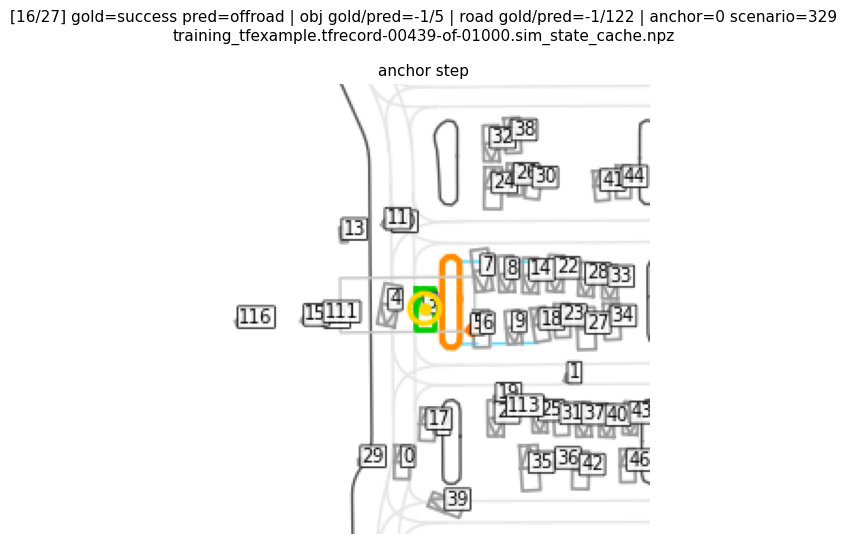

[17/27] gold=offroad pred=success | obj gold/pred=-1/3 | road gold/pred=79/81 | anchor=7 failure_step=28 scenario=0
training_tfexample.tfrecord-00185-of-01000.scenario_206.sim_state_cache.npz


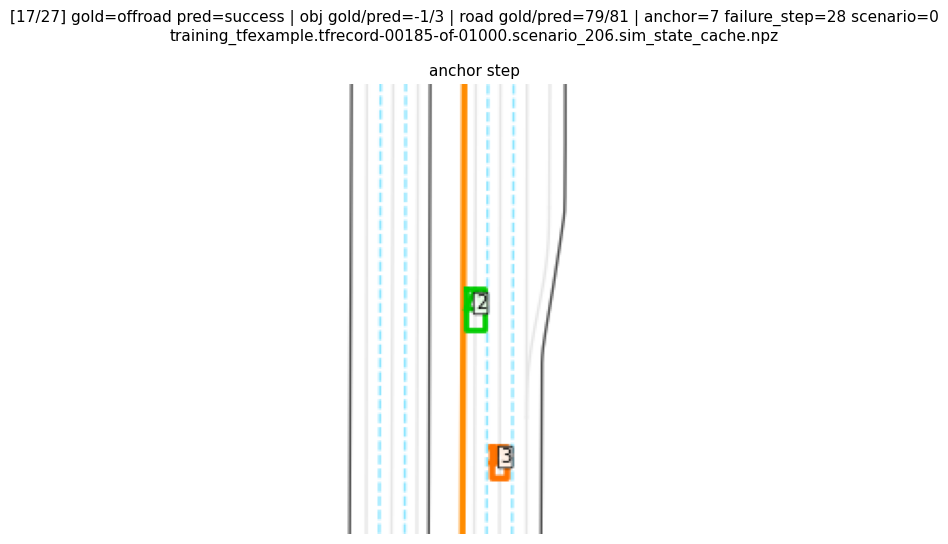

[18/27] gold=offroad pred=success | obj gold/pred=-1/2 | road gold/pred=45/45 | anchor=30 failure_step=38 scenario=0
training_tfexample.tfrecord-00477-of-01000.scenario_177.sim_state_cache.npz


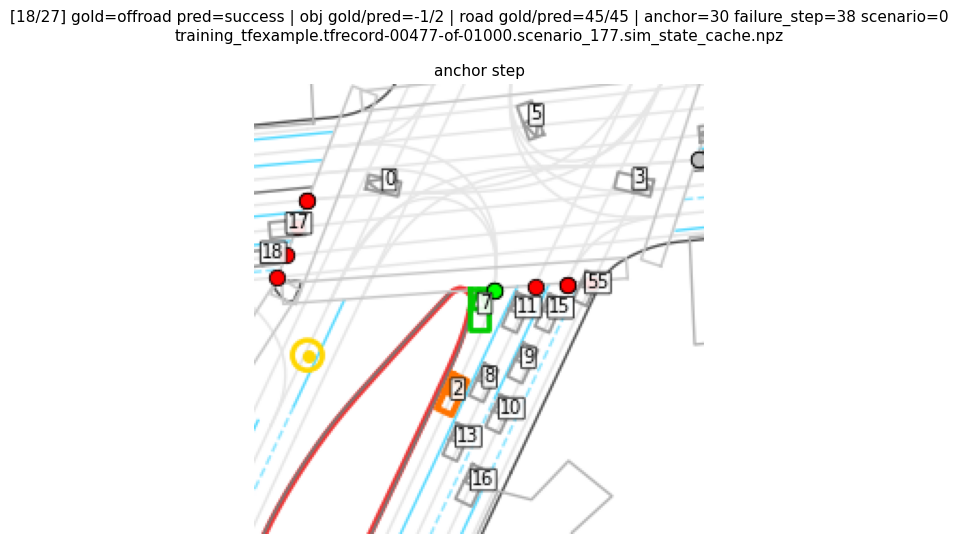

[19/27] gold=offroad pred=offroad | obj gold/pred=-1/4 | road gold/pred=1/74 | anchor=35 failure_step=62 scenario=0
training_tfexample.tfrecord-00370-of-01000.scenario_282.sim_state_cache.npz


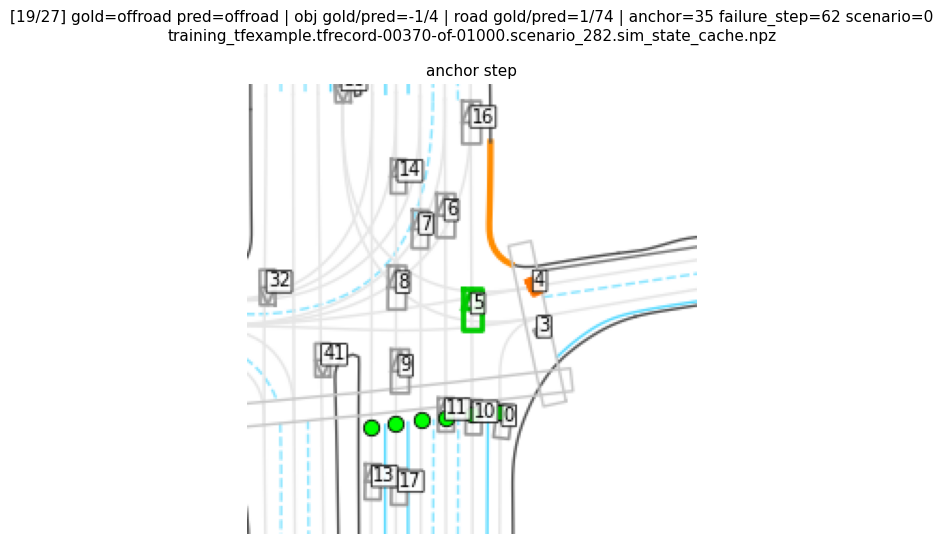

[20/27] gold=offroad pred=offroad | obj gold/pred=-1/3 | road gold/pred=1/64 | anchor=8 failure_step=37 scenario=0
training_tfexample.tfrecord-00258-of-01000.scenario_142.sim_state_cache.npz


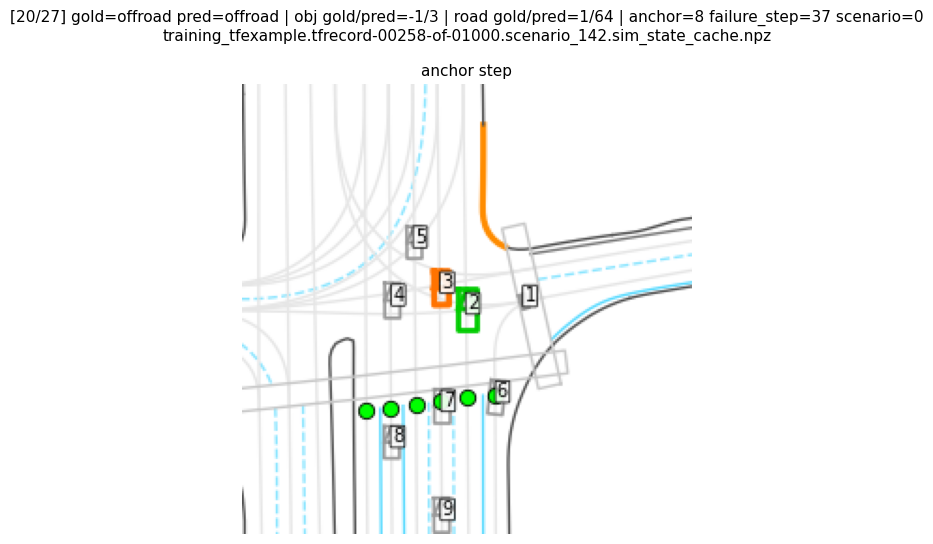

[21/27] gold=offroad pred=success | obj gold/pred=-1/20 | road gold/pred=118/118 | anchor=42 failure_step=78 scenario=0
training_tfexample.tfrecord-00486-of-01000.scenario_055.sim_state_cache.npz


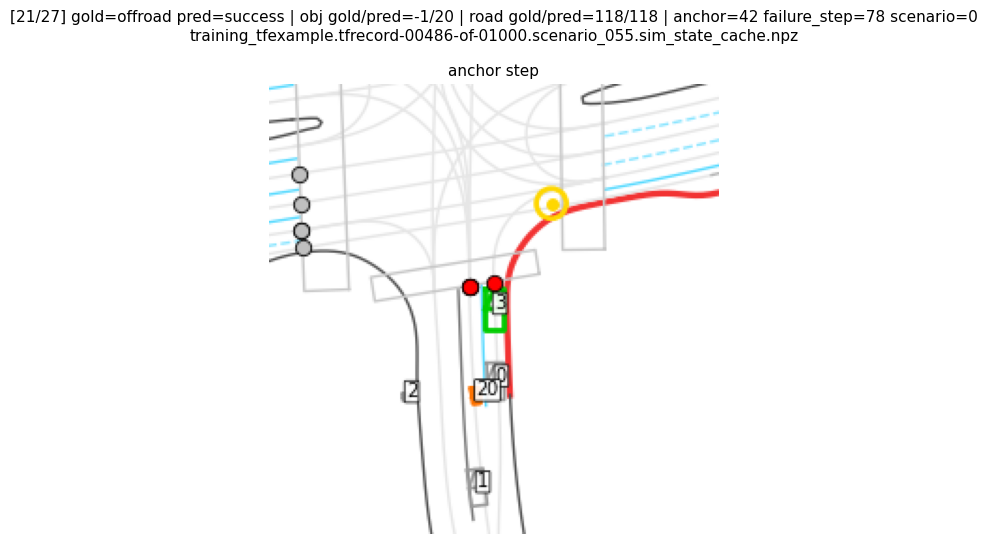

[22/27] gold=offroad pred=success | obj gold/pred=-1/0 | road gold/pred=23/23 | anchor=33 failure_step=77 scenario=0
training_tfexample.tfrecord-00459-of-01000.scenario_416.sim_state_cache.npz


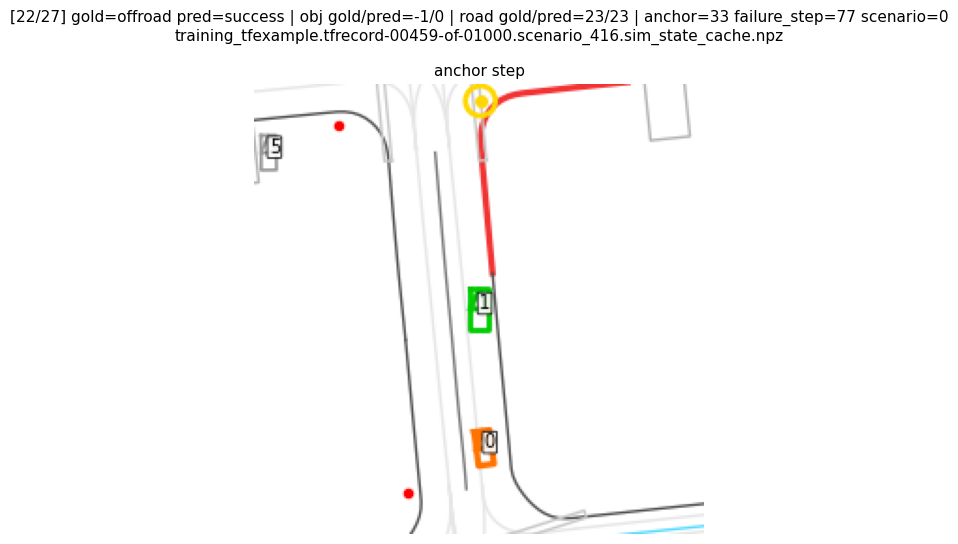

[23/27] gold=collision pred=offroad | obj gold/pred=5/5 | road gold/pred=-1/32 | anchor=0 failure_step=30 scenario=0
training_tfexample.tfrecord-00001-of-01000.scenario_347.sim_state_cache.npz


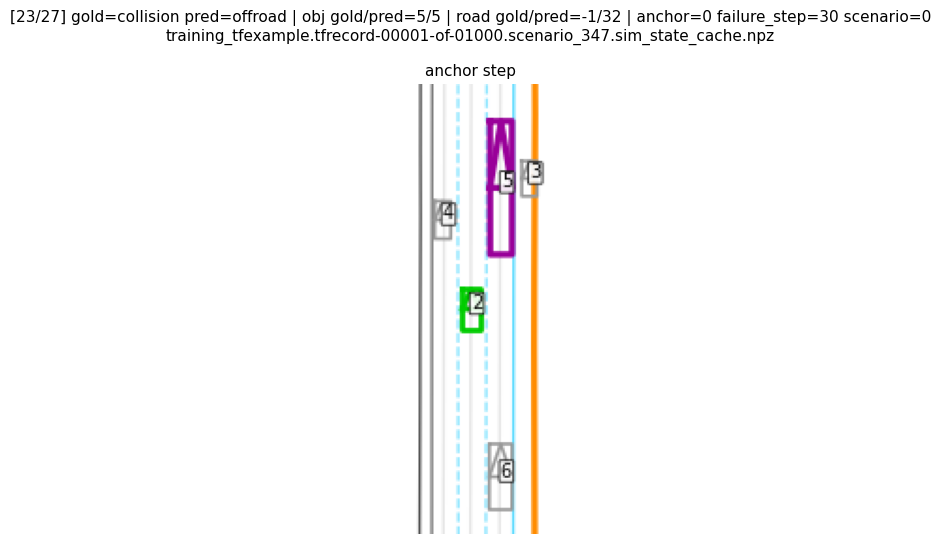

Next batch starts at 24. Re-run this cell to continue.


In [8]:
if "failed_df" not in globals():
    failed_df = df[df["failed"]].reset_index(drop=True)
if "_failed_viz_offset" not in globals():
    _failed_viz_offset = 0

if failed_df.empty:
    print("No failed predictions in the evaluated validation samples.")
else:
    start = int(_failed_viz_offset)
    end = min(start + int(MAX_FAILED_TO_VISUALIZE), len(failed_df))
    if start >= len(failed_df):
        print(
            f"Reached the end of failed cases ({len(failed_df)}). "
            "Run `_failed_viz_offset = 0` and re-run this cell to start over."
        )
    else:
        batch_df = failed_df.iloc[start:end]
        print(f"Showing failed cases {start}..{end - 1} / {len(failed_df) - 1}")
        display(batch_df)
        for viz_i, row in batch_df.iterrows():
            time_label = f"anchor={row['anchor_step']}"
            if str(row["gold_reason"]) != "success" and int(row["failure_step"]) >= 0:
                time_label += f" failure_step={int(row['failure_step'])}"
            title = (
                f"[{viz_i}/{len(failed_df) - 1}] gold={row['gold_reason']} pred={row['pred_reason']} | "
                f"obj gold/pred={row['gold_object_id']}/{row['pred_object_id']} | "
                f"road gold/pred={row['gold_road_id']}/{row['pred_road_id']} | "
                f"{time_label} scenario={row['scenario_idx']}\n"
                f"{Path(row['cache_path']).name}"
            )
            print(title)
            anchor_image, video_frames = visualize_failed_case(row, num_frames=VIZ_NUM_FRAMES, stride=VIZ_FRAME_STRIDE)
            show_case(anchor_image, video_frames, title=title)
        _failed_viz_offset = end
        if _failed_viz_offset >= len(failed_df):
            print(f"Done. Showed all {len(failed_df)} failed cases. `_failed_viz_offset = 0` to restart.")
        else:
            print(f"Next batch starts at {_failed_viz_offset}. Re-run this cell to continue.")